# Monte Carlo Portfolio Risk Simulation: Dhaka Stock Exchange
Munzeleen Sarwar

Hypothetical portfolio: Tk 1,000,000, equal weight across 11 DSE stocks (BATBC, BXPHARMA, CITYBANK, DBH, EBL, ROBI, ACI, BEXIMCO, FUWANGCER, GEMINISEA, SEAPEARL). Two methods, 10,000 simulations each, seed 42: correlated Geometric Brownian Motion and historical bootstrap. Horizons: 21, 63 and 252 trading days.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TICKERS = ['BATBC','BXPHARMA','CITYBANK','DBH','EBL','ROBI','ACI','BEXIMCO','FUWANGCER','GEMINISEA','SEAPEARL']
START = 1_000_000.0
N_SIMS, SEED = 10_000, 42
HORIZONS = [21, 63, 252]

/tmp/dsevenv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. Load the price data
Prices are the unadjusted daily closing prices published by the Dhaka Stock Exchange, downloaded by `scripts/fetch_data.py` and saved in `data/`.

In [2]:
frames = {t: pd.read_csv(f'data/{t}.csv', parse_dates=['date']).set_index('date') for t in TICKERS}
closes = pd.DataFrame({t: frames[t]['close'] for t in TICKERS}).sort_index()
volumes = pd.DataFrame({t: frames[t]['volume'] for t in TICKERS}).sort_index()
print('window:', closes.index.min().date(), 'to', closes.index.max().date())
print('trading days:', len(closes), '| missing values:', int(closes.isna().sum().sum()))
closes.head(3)

window: 2024-11-03 to 2026-10-15
trading days: 469 | missing values: 0


,BATBC,BXPHARMA,CITYBANK,DBH,EBL,ROBI,ACI,BEXIMCO,FUWANGCER,GEMINISEA,SEAPEARL
date,,,,,,,,,,,
2024-11-03,365.6,74.2,21.7,38.9,24.6,26.8,130.9,115.6,12.4,184.9,37.0
2024-11-04,371.9,74.1,21.7,40.0,24.9,27.3,135.1,115.6,12.9,199.8,37.5
2024-11-05,370.1,76.1,22.3,39.9,24.9,27.2,142.5,115.6,13.8,208.2,37.7


## 2. Data coverage and problem counts

In [3]:
daily = closes.pct_change().dropna()
cov_rows = []
for t in TICKERS:
    cov_rows.append({'ticker': t, 'rows': int(closes[t].notna().sum()),
                     'pct_zero_return_days': round(100 * (daily[t] == 0).mean(), 2),
                     'zero_volume_days': int((volumes[t] == 0).sum()),
                     'median_daily_volume': float(volumes[t].median()),
                     'falls_beyond_9pct': int((daily[t] < -0.09).sum()),
                     'rises_beyond_9pct': int((daily[t] > 0.09).sum())})
coverage = pd.DataFrame(cov_rows)
coverage

,ticker,rows,pct_zero_return_days,zero_volume_days,median_daily_volume,falls_beyond_9pct,rises_beyond_9pct
0,BATBC,469,1.92,3,94192.0,0,0
1,BXPHARMA,469,2.14,2,461111.0,0,1
2,CITYBANK,469,20.30,3,2678853.0,2,0
3,DBH,469,7.48,2,126767.0,1,0
4,EBL,469,23.50,2,1008355.0,2,0
5,ROBI,469,15.60,2,1715453.0,0,0
6,ACI,469,2.35,3,50239.0,1,0
7,BEXIMCO,469,81.62,149,3.0,13,4
8,FUWANGCER,469,14.74,2,933159.0,0,1
9,GEMINISEA,469,1.28,2,38259.0,2,5


BEXIMCO stands out: most days have no price change and the median daily volume is close to zero. Section 8 lists all data problems with counts.

## 3. Per-stock statistics and correlation

In [4]:
logret = np.log(closes / closes.shift(1)).dropna()
stats = pd.DataFrame({
    'total_return_pct': (closes.iloc[-1] / closes.iloc[0] - 1) * 100,
    'annualised_return_pct': logret.mean() * 252 * 100,
    'annualised_volatility_pct': logret.std(ddof=1) * np.sqrt(252) * 100,
    'worst_day_pct': (np.expm1(logret.min())) * 100,
    'sharpe_rf_0pct': (logret.mean() * 252) / (logret.std(ddof=1) * np.sqrt(252)),
}).round(2)
stats

,total_return_pct,annualised_return_pct,annualised_volatility_pct,worst_day_pct,sharpe_rf_0pct
BATBC,-40.21,-27.69,23.19,-8.94,-1.19
BXPHARMA,96.50,36.37,33.00,-6.38,1.10
CITYBANK,36.41,16.72,29.38,-16.67,0.57
DBH,0.51,0.28,25.25,-9.01,0.01
EBL,-6.91,-3.86,26.28,-20.74,-0.15
ROBI,10.82,5.53,22.35,-6.76,0.25
ACI,37.74,17.24,29.24,-14.07,0.59
BEXIMCO,-81.14,-89.83,36.64,-9.99,-2.45
FUWANGCER,-7.26,-4.06,39.60,-7.41,-0.10
GEMINISEA,-41.64,-29.00,40.11,-9.98,-0.72


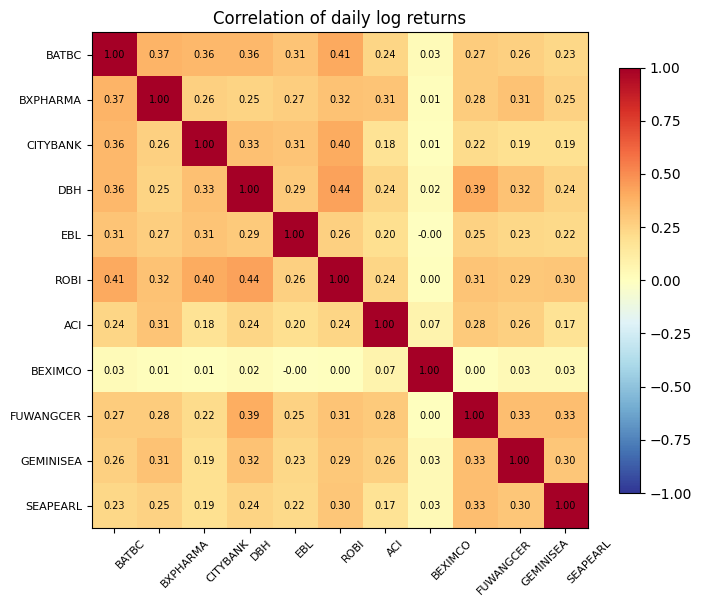

In [5]:
corr = logret.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.values, cmap='RdYlBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(11), corr.columns, rotation=45, ha='left', fontsize=8)
ax.set_yticks(range(11), corr.index, fontsize=8)
for i in range(11):
    for j in range(11):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.85)
ax.set_title('Correlation of daily log returns')
plt.show()

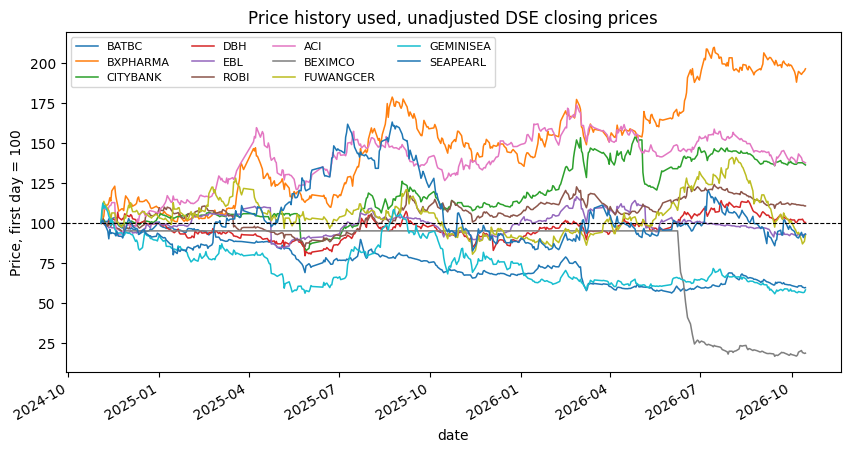

In [6]:
norm = closes / closes.iloc[0] * 100
norm.plot(figsize=(10, 5), lw=1.1)
plt.axhline(100, color='black', lw=0.8, ls='--')
plt.ylabel('Price, first day = 100')
plt.legend(ncol=4, fontsize=8)
plt.title('Price history used, unadjusted DSE closing prices')
plt.show()

## 4. Risk summary function
VaR 95% is the loss exceeded in 5% of simulations. CVaR 95% is the average loss in that worst 5%.

In [7]:
def summarise(endings):
    rets = endings / START - 1.0
    out = {f'p{p}_tk': float(np.percentile(endings, p)) for p in (1, 5, 25, 50, 75, 95, 99)}
    out['prob_loss_pct'] = float(100 * np.mean(rets < 0))
    out['prob_loss_over_10pct'] = float(100 * np.mean(rets < -0.10))
    out['prob_loss_over_20pct'] = float(100 * np.mean(rets < -0.20))
    for level in (95, 99):
        var = float(np.percentile(rets, 100 - level))
        out[f'var{level}_tk'] = round(-var * START)
        out[f'cvar{level}_tk'] = round(-rets[rets <= var].mean() * START)
    return out

## 5. Method 1: correlated Geometric Brownian Motion
The Cholesky decomposition of the covariance matrix keeps the real correlations in the simulated returns.

In [8]:
mu = logret.mean().values
cov = logret.cov().values
chol = np.linalg.cholesky(cov)
rng = np.random.default_rng(SEED)
max_h = 252
endings = {h: np.empty(N_SIMS) for h in HORIZONS}
fan_days = [0] + list(range(6, max_h + 1, 6)) + [max_h]
fan = {d: np.empty(N_SIMS) for d in fan_days}
max_dd = np.empty(N_SIMS)
done = 0
while done < N_SIMS:
    b = min(1000, N_SIMS - done)
    z = rng.standard_normal((b, max_h, 11))
    daily_log = (mu - 0.5 * np.diag(cov)) + z @ chol.T
    port = np.exp(np.cumsum(daily_log, axis=1)).mean(axis=2)
    paths = START * port
    for h in HORIZONS:
        endings[h][done:done + b] = paths[:, h - 1]
    for d in fan_days:
        fan[d][done:done + b] = START if d == 0 else paths[:, d - 1]
    full = np.hstack([np.full((b, 1), START), paths])
    run_max = np.maximum.accumulate(full, axis=1)
    max_dd[done:done + b] = ((run_max - full) / run_max).max(axis=1)
    done += b
gbm_results = pd.DataFrame({h: summarise(endings[h]) for h in HORIZONS}).T
gbm_results

,p1_tk,p5_tk,p25_tk,p50_tk,p75_tk,p95_tk,p99_tk,prob_loss_pct,prob_loss_over_10pct,prob_loss_over_20pct,var95_tk,cvar95_tk,var99_tk,cvar99_tk
21,881821.991087,914931.584122,959774.619881,993272.313825,1.026999e+06,1.079915e+06,1.115673e+06,55.54,2.42,0.00,85068.0,104858.0,118178.0,135614.0
63,797255.832785,848966.338884,924979.045114,981209.217879,1.041386e+06,1.135321e+06,1.206298e+06,58.53,16.39,1.16,151034.0,181221.0,202744.0,225272.0
252,627688.262031,711117.419774,842832.601894,952265.240288,1.076754e+06,1.284195e+06,1.462150e+06,60.27,37.90,16.51,288883.0,337436.0,372312.0,405927.0


GBM 252 day maximum drawdown: median 19.12%, 95th percentile 34.26%


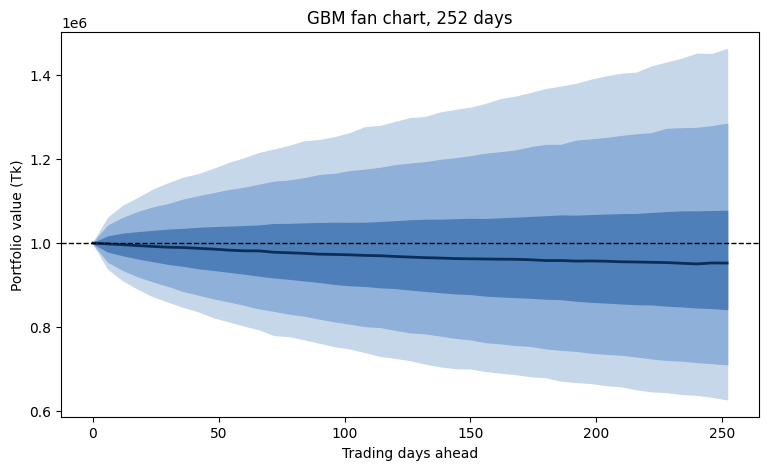

In [9]:
print('GBM 252 day maximum drawdown: median %.2f%%, 95th percentile %.2f%%' % (
    100 * np.median(max_dd), 100 * np.percentile(max_dd, 95)))
fan_df = pd.DataFrame({d: fan[d] for d in fan_days}).T
fan_pct = fan_df.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99], axis=1).T
fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(fan_pct.index, fan_pct[0.01], fan_pct[0.99], color='#c7d7ea')
ax.fill_between(fan_pct.index, fan_pct[0.05], fan_pct[0.95], color='#8fb0d8')
ax.fill_between(fan_pct.index, fan_pct[0.25], fan_pct[0.75], color='#4f7fb8')
ax.plot(fan_pct.index, fan_pct[0.5], color='#0b2e59', lw=2)
ax.axhline(START, color='black', lw=1, ls='--')
ax.set_title('GBM fan chart, 252 days')
ax.set_xlabel('Trading days ahead')
ax.set_ylabel('Portfolio value (Tk)')
plt.show()

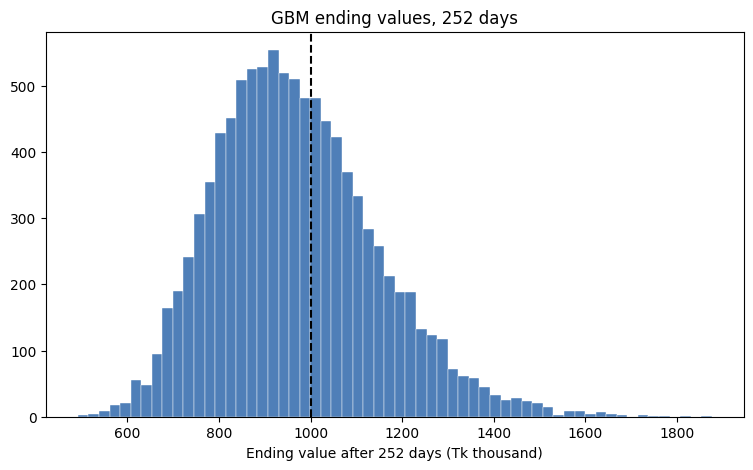

In [10]:
plt.figure(figsize=(9, 5))
plt.hist(endings[252] / 1000, bins=60, color='#4f7fb8', edgecolor='white', lw=0.3)
plt.axvline(1000, color='black', lw=1.5, ls='--')
plt.xlabel('Ending value after 252 days (Tk thousand)')
plt.title('GBM ending values, 252 days')
plt.show()

## 6. Method 2: historical bootstrap
Actual daily portfolio returns are resampled with replacement and compounded.

In [11]:
port_daily = np.expm1(logret).mean(axis=1).values
rng = np.random.default_rng(SEED)
boot_results = {}
boot_endings = {}
for h in HORIZONS:
    idx = rng.integers(0, len(port_daily), size=(N_SIMS, h))
    ends = START * np.prod(1.0 + port_daily[idx], axis=1)
    boot_endings[h] = ends
    boot_results[h] = summarise(ends)
pd.DataFrame(boot_results).T

,p1_tk,p5_tk,p25_tk,p50_tk,p75_tk,p95_tk,p99_tk,prob_loss_pct,prob_loss_over_10pct,prob_loss_over_20pct,var95_tk,cvar95_tk,var99_tk,cvar99_tk
21,884167.355277,917769.665946,965428.807926,997956.969215,1.031060e+06,1.081293e+06,1.118154e+06,51.64,2.19,0.00,82230.0,102663.0,115833.0,132568.0
63,808444.123934,858815.767947,934628.804934,990722.662363,1.048906e+06,1.135517e+06,1.206188e+06,54.48,13.38,0.74,141184.0,172131.0,191556.0,214937.0
252,646423.539107,729794.237309,856452.779153,961600.598778,1.083105e+06,1.273812e+06,1.443791e+06,58.77,35.43,13.84,270206.0,320693.0,353576.0,395525.0


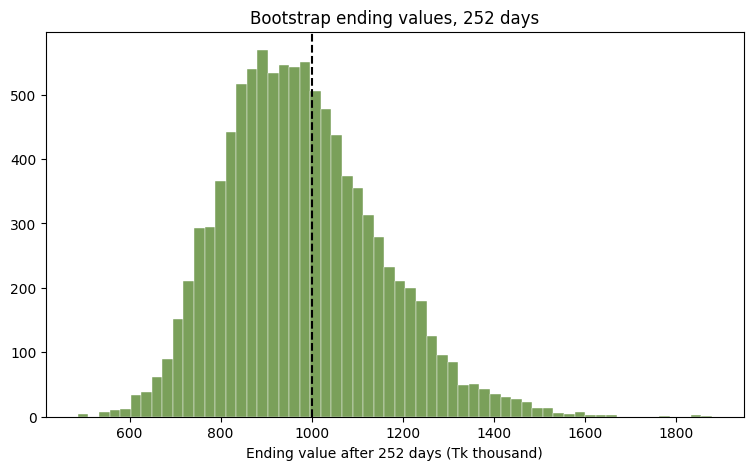

In [12]:
plt.figure(figsize=(9, 5))
plt.hist(boot_endings[252] / 1000, bins=60, color='#7aa05a', edgecolor='white', lw=0.3)
plt.axvline(1000, color='black', lw=1.5, ls='--')
plt.xlabel('Ending value after 252 days (Tk thousand)')
plt.title('Bootstrap ending values, 252 days')
plt.show()

## 7. Comparison at 252 days

In [13]:
compare = pd.DataFrame({
    'GBM': {k: gbm_results.loc[252, k] for k in ('p50_tk', 'prob_loss_pct', 'var95_tk', 'cvar95_tk', 'var99_tk', 'cvar99_tk')},
    'Bootstrap': {k: boot_results[252][k] for k in ('p50_tk', 'prob_loss_pct', 'var95_tk', 'cvar95_tk', 'var99_tk', 'cvar99_tk')},
})
compare

,GBM,Bootstrap
p50_tk,952265.240288,961600.598778
prob_loss_pct,60.270000,58.770000
var95_tk,288883.000000,270206.000000
cvar95_tk,337436.000000,320693.000000
var99_tk,372312.000000,353576.000000
cvar99_tk,405927.000000,395525.000000


## 8. Limitations and data problems
- History is shorter than planned. The plan was January 2021 to October 2026. The DSE archive in its current form starts on 3 November 2024, and a published archive for the earlier years was checked and rejected: it contains 666 daily moves above 12% across the 11 stocks in 2021 and 2022, in a market with a daily circuit breaker of about 10%, plus duplicate dates with conflicting closes.
- Floor prices held many DSE prices fixed from 2022 into early 2024. In the rejected archive, BATBC, ROBI, ACI and BEXIMCO each have only one unique closing price in the whole of 2023.
- BEXIMCO barely traded: 149 zero volume days, median daily volume of 3 shares, 81.6% of days with no price change, price fixed at Tk 110.1 through calendar 2025, then a fall to Tk 21.8.
- GEMINISEA is category Z and thinly traded, median daily volume 38,259 shares, with 5 rises and 2 falls beyond 9% in the window.
- FUWANGCER is a small category B ceramics stock, third highest volatility in the set, 14.7% of days with no price change.
- Prices are unadjusted. CITYBANK fell 16.67% on 2025-05-24, EBL fell 20.74% on 2025-04-24 and ACI fell 14.07% on 2024-11-18. Each follows a zero volume day and matches a dividend record date pattern, so part of each fall is a dividend reset recorded as a price loss. No adjustment was made and no dividend income is added in the simulation.
- The daily circuit breaker of about 10% truncates real moves: across the set there were 18 rises beyond 9% and 22 falls beyond 9% in 469 days.
- GBM assumes normal returns and constant volatility. The bootstrap assumes the last 469 days repeat, and it splits up real runs of bad days.
- Costs, taxes and the difficulty of trading thin stocks are not included. Sharpe ratios use a risk free rate of 0%.